## TX00DZ62-3009 Tapaaminen 21-22.10.2025


## SQL-tietokannan käsittely Python-ohjelmassa

Tässä käsitellään tapoja lukea ja kirjoittaa SQLite -kirjaston avulla toteutetun relaatiotietokannan tietoja. Käsittelytapa on samankaltainen myös kun käytetään perinteistä tietokantajärjestelmää (esim. erillinen palvelin, jossa toimii relaatiotietokannan hallintajärjestelmä).

SQLite -relaatiotietokannassa olevaa tietoa voidaan käsitellä sqlite3 -kirjaston avulla.

Tyypilliset askeleet tietokannan käsittelyssä ovat:

* tietokantaan kytkeytyminen connect() -metodilla, joka palauttaa yhteyttä esittävän objektin
* cursor -objektin luominen yhteysobjektin cursor() -metodilla
* SQL-lauseiden suorittaminen cursor -objektin execute() -metodilla
* mahdollisesti tehtyjen muutosten tekeminen pysyviksi yhteysobjektin commit() -metodilla
* yhteyden sulkeminen kutsumalla yhteysobjektin close() -metodilla

Esimerkin aluksi luetaan verkosta kansanedustajiin liittyvää json-muotoista dataa edellisellä kerralla käsitellyllä tavalla.

In [1]:
import json
import urllib.request

pyynto = urllib.request.urlopen("http://users.metropolia.fi/~peterh/mps.json")
data = pyynto.read()

eduskunta = json.loads(data)

Otetaan aluksi käyttöön sqlite3 -paketti.

Tämän jälkeen kytkeydytään tietokantaan ja luodaan cursor -objekti.

Tuhotaan mahdollisesti aiemmalla notebookin suorituksella luotu eduskunta -taulu suorittamalla SQL-komento cursor-objektin .execute() -metodilla jonka jälkeen tehdään muutokset pysyviksi ja suljetaan tietokantayhteys. Mikäli tietokantaa ei ollut ennestään olemassa, se luodaan kytkeytymisen yhteydessä. Sqlite3 -kirjastoa käyttäessä tietokantaa vastaa tiedostojärjestelmään syntyvä tiedosto, tässä esimerkissä 'mps.db'.

Esimerkei

In [2]:
import sqlite3

conn = sqlite3.connect('mps.db')
cursor = conn.cursor()
cursor.execute('''
    drop table if exists eduskunta
''')
conn.commit()
conn.close()

Seuraavaksi luodaan taulu eduskunta suorittamalla SQL-komento.

Esimerkeissä yhteys tietokantaan luodaan ja katkaistaan jokaisen solun alussa ja lopussa jotta solut voi suorittaa toisistaan riippumatta, toedellisessa koodissa näin ei tehtäisi.


In [3]:
conn = sqlite3.connect('mps.db')
cursor = conn.cursor()
cursor.execute('''
    create table eduskunta (
        personnumber integer,
        last text,
        first text,
        party text,
        constituency text,
        bornyear integer
    )
''')
conn.commit()
conn.close()

Suoritetaan tietokantahaku, jonka tuloksiin pääse käsiksi cursor -objektin metodeilla. fetchall() -metodi palauttaa listan, jossa palautetut rivit ovat elementteinä. Tässä tapauksessa lista on tyhjä, koska tietokantaan ei ole kirjoitettu mitään.

In [4]:
conn = sqlite3.connect('mps.db')
cursor = conn.cursor()

cursor.execute('''
    select * from eduskunta
''')
print(cursor.fetchall())

conn.commit()
conn.close()

[]


Tietokantahaun tuloksiin pääse käsiksi cursor -objektin metodeilla. fetchall() -metodi palauttaa listan, jossa palautetut rivit ovat elementteinä.

In [5]:
conn = sqlite3.connect('mps.db')
cursor = conn.cursor()

cursor.execute('''
    select * from eduskunta
''')

print(cursor.fetchall())
conn.close()

[]


SQL:n insert toimii normaalisti. Merkkijonomuuttujien käyttö insert-lauseessa ei ole suositeltavaa SQL-injektiohyökkäysmahdollisuuden takia - omassa ympäristössä suoritettavien notebookien kannalta sillä ei tosin ole merkitystä.

Tässä käydään läpi kaikki listassa eduskunta olevat elementit (kansanedustajat) ja tiedot lisätään kansanedustaja  kerrallaan tietokantaan.

In [6]:
conn = sqlite3.connect('mps.db')
cursor = conn.cursor()

for ke in eduskunta:
    cursor.execute("insert into eduskunta values (?,?,?,?,?,?)",
                   (ke['personNumber'], ke['last'], ke['first'], ke['party'], ke['constituency'], ke['bornYear']))

conn.commit()
conn.close()

Esimerkissä haetaan ehdon täyttävistä kansanedustajista puoluetieto. Tietoa jatkokäsitellään Python-ohjelmassa (esimerkin pystyisi toteuttamaan myös SQL-lauseilla).

In [7]:
conn = sqlite3.connect('mps.db')
cursor = conn.cursor()

cursor.execute('''
    select party from eduskunta where bornyear > 1985
''')
results = cursor.fetchall()
print(results)

conn.close()

nuorisot = {}
for r in results:
    if not r[0] in nuorisot:
        nuorisot[r[0]] = 0
    nuorisot[r[0]] += 1
print(nuorisot)

[('kesk',), ('kesk',), ('kesk',), ('vas',), ('ps',), ('vihr',), ('kok',), ('sd',), ('kesk',), ('vihr',), ('ps',), ('kesk',), ('sd',), ('kesk',), ('kok',), ('sd',), ('sd',), ('kesk',), ('vihr',), ('kok',), ('vas',), ('ps',), ('kok',), ('vihr',), ('ps',), ('vihr',)]
{'kesk': 7, 'vas': 2, 'ps': 4, 'vihr': 5, 'kok': 4, 'sd': 4}


## Nympy-kirjaston perusteet

(Pahoittelut kielen vaihtumisesta...)

NumPy is a very widely used package for manipulating multidimensional arrays in Python. It includes a lot of useful and efficient functionality for doing computations on large data sets. The syntax of NumPy arrays resembles that of Python lists quite closely, so it is easy to get started with NumPy.

For an overview of the targets and design of NumPy see article in Nature at: https://www.nature.com/articles/s41586-020-2649-2. A nice tutorial to get started with NumPy is at https://numpy.org/devdocs/user/quickstart.html, section "The Basics". Definite guide for NumPy is https://numpy.org/doc/stable/index.html

To use NumPy package, it must be installed and imported. To install with Anaconda, click on Environments, select your environment for this course, choose "Not installed" in the package listing window, and search for "numpy". Select numpy package for installation, and click on Install. It is customary to import NumPy with short name "np":

In [8]:
import numpy as np

Matplotlib is needed in this notebook for visualisations. It can be installed in the same way as numpy and imported as plt.

In [9]:
import matplotlib.pyplot as plt

### Creating NumPy arrays

Typical ways to create NumPy arrays are:

* from Python lists
* using NumPy functions
* by reading in data, for example images, from file system

#### Create NumPy arrays from Python lists

NumPy arrays can be created from one- or multidimensional Python lists. Note that lists must be of single type, ie. can no contain strings and floating point numbers mixed. (Usually it does not make sense to use NumPy for storing strings anyways).

In [10]:
credits = [5, 5, 5, 3, 5, 2]
cre = np.array(credits)
print(cre)

grades = [1, 5, 5, 4, 2, 5]
gra = np.array(grades)

courses = [ credits, grades ] # two-dimensional Python list
print(courses)
cou = np.array(courses)
print(cou)
print(cou[1,3]) # indices separated by commas, no need for separate []s like when addressing Python lists of lists

[5 5 5 3 5 2]
[[5, 5, 5, 3, 5, 2], [1, 5, 5, 4, 2, 5]]
[[5 5 5 3 5 2]
 [1 5 5 4 2 5]]
4


#### Create NumPy arrays with NumPy functions

NumPy arrays with given dimensions can be created with a selection of NumPy functions. The dimensions are specified using Python tuples (a collection of comma-separated values in parenthesis, for example (3,4) specifies an array with 3 rows and 4 columns).

In [11]:
a = np.zeros((3,4)) # all zeros
b = np.ones((3,4)) # all ones
c = np.empty((3,4)) # not initialized
d = np.arange(0,60,5) # range of values
e = np.linspace(0,10,21) # evenly-spaced values from 0 to 10, 21 values
f = np.random.rand(3,5) # 3 by 5 matrix of uniform random numbers from 0 to 1
print(a)
print(b)
print(c)
print(d)
print(e)
print(f)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[ 0  5 10 15 20 25 30 35 40 45 50 55]
[ 0.   0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5
  7.   7.5  8.   8.5  9.   9.5 10. ]
[[0.54516837 0.29974646 0.07885878 0.48186054 0.09363076]
 [0.97373305 0.56922442 0.35930231 0.24837976 0.01037534]
 [0.79874781 0.1903829  0.61842044 0.61123533 0.7889995 ]]


#### Create NumPy array from csv file

Data can be read into numpy array from file, for example using genfromtxt(). In this example we read in esim.csv file that has the same data as previously but we need to skip the last column that contains string data. Here the decimal commas are replaced with periods (65,0 -> 65.0)

For more on genfromtxt(), see https://numpy.org/doc/stable/reference/generated/numpy.genfromtxt.html

In [12]:
from numpy import genfromtxt
mydata = genfromtxt('esim.csv', delimiter=';', usecols=(0,1,2))
print(mydata)

[[100.1 198.   44. ]
 [ 80.  182.8  43. ]
 [ 60.  170.   39. ]
 [ 65.  161.   37. ]]


#### NumPy array attributes

Array "shape" gives a tuple of dimensions, "ndim" gives the number of elements in shape, ie. dimensionality, "size" total number of elements in the array, and "dtype" the type of elements. Note that a NumPy array only has one type of elements (whereas a Python list may contain ints, floats, strings etc.). For one-dimensional arrays, the shape can end with comma. Reasons for this (a bit confusing) convention are explained here: https://stackoverflow.com/questions/46134891/why-an-extra-comma-in-the-shape-of-a-single-index-numpy-array

To change the dimensions of an array, use reshape() and give new dimensions as a tuple of parameters, ie. enclose them in parenthesis. Dimension -1 means that the dimension is computed based on other dimensions. Note that not all reshaping operations make sense: it is not possible to reshape an array with shape (2,5) into (3,4) - element count doesn't match. Reshaping doesn't cause data to be copied, it merely changes that way the data is viewed internally in numpy.

To transpose a matrix, ie. swap rows and columns, do .T

In [13]:
a = np.zeros((3,5,2)) # all zeros
print("a attributes")
print(a.shape)
print(a.shape[0], a.shape[1])
print(a.ndim)
print(a.size)
print(a.dtype)

a attributes
(3, 5, 2)
3 5
3
30
float64


In [14]:
print("d shape")
d = np.arange(0,60,5) # range of values
print(d.shape)

print("d reshaped")
e = d.reshape((4,3))
print(e)

print("d reshaped again")
f = d.reshape((6,-1))
print(f.shape)
print(f)

print("d reshaped once more")
g = d.reshape(3,2,2)
print(g.shape)
print(g)

print("transpose")
print(e)
print(e.T)

# h = d.reshape(3,5) -> cannot reshape array of size 12 into shape (3,5)

d shape
(12,)
d reshaped
[[ 0  5 10]
 [15 20 25]
 [30 35 40]
 [45 50 55]]
d reshaped again
(6, 2)
[[ 0  5]
 [10 15]
 [20 25]
 [30 35]
 [40 45]
 [50 55]]
d reshaped once more
(3, 2, 2)
[[[ 0  5]
  [10 15]]

 [[20 25]
  [30 35]]

 [[40 45]
  [50 55]]]
transpose
[[ 0  5 10]
 [15 20 25]
 [30 35 40]
 [45 50 55]]
[[ 0 15 30 45]
 [ 5 20 35 50]
 [10 25 40 55]]


#### Slicing

Slicing works with the principles as with Python lists (and lists of lists). See "Indexing, Slicing and Iterating" in https://numpy.org/devdocs/user/quickstart.html#the-basics for more.

In [15]:
a = np.arange(0,60,5).reshape(4,3)
print("a")
print(a)
print("a[:,1]")
print(a[:,1])
print("a[1:,:]")
print(a[1:,:])
print("a[1:,-1]")
print(a[1:,-1])

a
[[ 0  5 10]
 [15 20 25]
 [30 35 40]
 [45 50 55]]
a[:,1]
[ 5 20 35 50]
a[1:,:]
[[15 20 25]
 [30 35 40]
 [45 50 55]]
a[1:,-1]
[25 40 55]


#### Operations with NumPy arrays

Arithmetic operations with NumPy arrays are performed in element-wise fashion - when for example doing addition, elements at corresponding locations are added. Note that would we use Python lists, we'd need to write loops to do this. When using NumPy, one usually tries to avoid loops and rather use NumPy operations - the operations are well optimized and can utilize processor vector instructions.

NumPy supports linear algebra operations, such as matrix multiplication - these operations have a particularily efficient implementations in NumPy. For a refresher on matrix multiplication, see "Multiplying a Matrix by Another Matrix" in https://www.mathsisfun.com/algebra/matrix-multiplying.html .

In NumPy, operands are automatically broadcasted to appropriate shapes - this allows us to write A + 1, where A is a NumPy array. Scalar 1 is broadcasted into the same shape as A, ie. an array with the same shape as A and full of 1s. Broadcasting works with lower-dimensional arrays, too. See "Broadcasting rules" at https://numpy.org/devdocs/user/quickstart.html#less-basic for more.

In [16]:

a = np.arange(0,50,5).reshape(2,5)
print("a")
print(a)
b = np.ones((2,5))
print("a+b and a-b")
print(a+b) # element-wise addition
print(a-b)

c = np.array([[3,3,3,3,3],[3,3,3,3,3]])
print("a * c")
print(a * c) # element-wise multiplication

print("scalar broadcasting")
print(a + 1) # scalar 1 is broadcasted to same shape as a
print(a * 3)

d = np.arange(0,9).reshape((3,3))
print(d)
e = np.eye(3,3) * 3 # eye -> matrix with diagonal element = 1, others 0. multiply with scalar
print(e)
print(d @ e) # matrix multiplication

a
[[ 0  5 10 15 20]
 [25 30 35 40 45]]
a+b and a-b
[[ 1.  6. 11. 16. 21.]
 [26. 31. 36. 41. 46.]]
[[-1.  4.  9. 14. 19.]
 [24. 29. 34. 39. 44.]]
a * c
[[  0  15  30  45  60]
 [ 75  90 105 120 135]]
scalar broadcasting
[[ 1  6 11 16 21]
 [26 31 36 41 46]]
[[  0  15  30  45  60]
 [ 75  90 105 120 135]]
[[0 1 2]
 [3 4 5]
 [6 7 8]]
[[3. 0. 0.]
 [0. 3. 0.]
 [0. 0. 3.]]
[[ 0.  3.  6.]
 [ 9. 12. 15.]
 [18. 21. 24.]]


#### Concatenate

NumPy arrays can be combined to form new arrays by concatenating (appending them) them across given axis.

In [17]:
a = np.arange(8).reshape(2,4)
print("a\n", a)
b = np.ones((2,4))
print("b\n", b)
c = np.concatenate((a, b), axis=0)
print("c\n", c)
print("example 1\n", np.concatenate((b, a), axis=0))
print("example 2\n", np.concatenate((a, b), axis=1))
print("example 3\n", np.concatenate((a, b), axis=None))

a
 [[0 1 2 3]
 [4 5 6 7]]
b
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]]
c
 [[0. 1. 2. 3.]
 [4. 5. 6. 7.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]
example 1
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [0. 1. 2. 3.]
 [4. 5. 6. 7.]]
example 2
 [[0. 1. 2. 3. 1. 1. 1. 1.]
 [4. 5. 6. 7. 1. 1. 1. 1.]]
example 3
 [0. 1. 2. 3. 4. 5. 6. 7. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Boolean arrays

Comparison of two NumPy arrays gives a NumPy array of boolean (True/False) elements. Note that broadcasting works - usually no need to create the full comparison array.

In [18]:
a = np.random.rand(2,4)
print("a\n", a)
b = a < 0.5 # 0.5 is broadcasted to shape (2,4) and each element is compared
print("b\n", b)
print(np.sum(b))
c = np.arange(8).reshape(2,4) * b # True - 1, False - 0
print(c)

a
 [[0.68735856 0.39949569 0.99357463 0.61260822]
 [0.50528178 0.59971518 0.88773925 0.667299  ]]
b
 [[False  True False False]
 [False False False False]]
1
[[0 1 0 0]
 [0 0 0 0]]


## Visualisointi matplotlib -kirjastolla

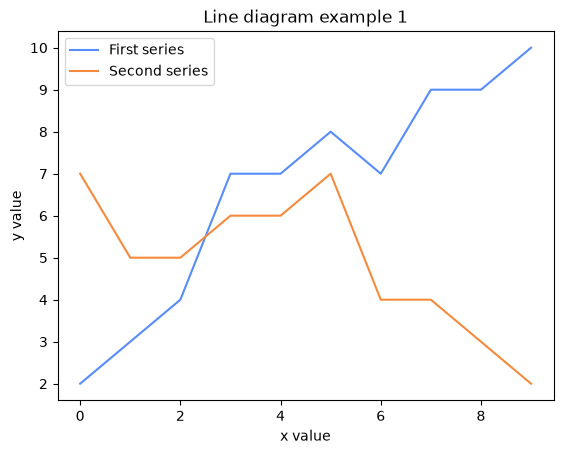

In [19]:
# np.array creates a new numpy array, in examples below from fixed data given as a Python list

lineplotdata1 = np.array([2,3,4,7,7,8,7,9,9,10])    #
lineplotdata2 = np.array([7,5,5,6,6,7,4,4,3,2])
plt.plot(lineplotdata1, label="First series")   # one data series only - x values are taken to be the indices
plt.plot(lineplotdata2, label="Second series")
plt.legend()    # top left-hand corner legend box created from .plot() label values
plt.title("Line diagram example 1")
plt.xlabel("x value")
plt.ylabel("y value")
plt.show()      # .show() not mandatory in all environments to draw the graphic

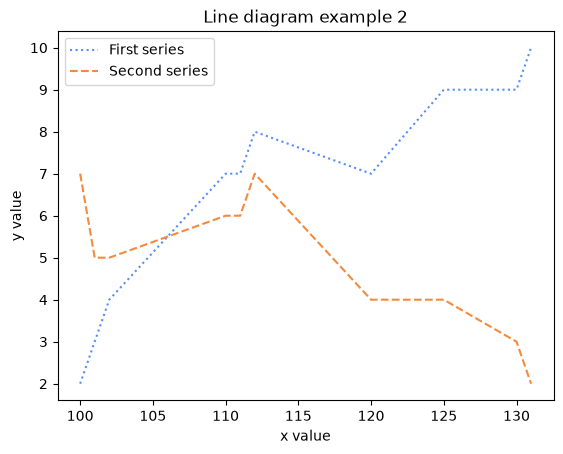

In [20]:
xvalues = [100,101,102,110,111,112,120,125,130,131]
# two arguments in .plot() - first is taken to be the xvalues and second the y values
plt.plot(xvalues, lineplotdata1, linestyle="dotted", label="First series")
plt.plot(xvalues, lineplotdata2, linestyle="dashed", label="Second series")
plt.legend()
plt.title("Line diagram example 2")
plt.xlabel("x value")
plt.ylabel("y value")
plt.show()

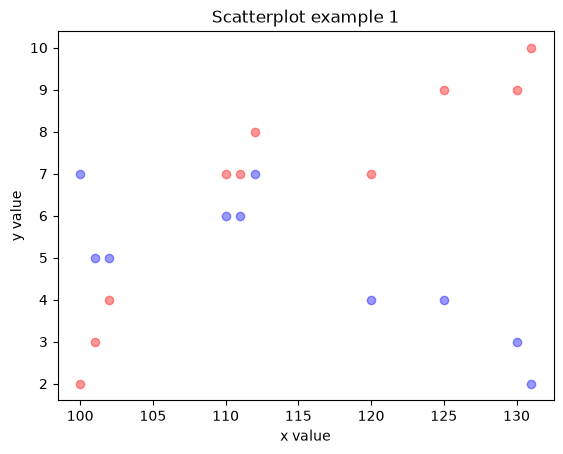

In [21]:
plt.scatter(xvalues, lineplotdata1, c="r", alpha=0.4) # for scatter must give two series
plt.scatter(xvalues, lineplotdata2, c="b", alpha=0.4) # c for colour
plt.title("Scatterplot example 1")
plt.xlabel("x value")
plt.ylabel("y value")
plt.show()

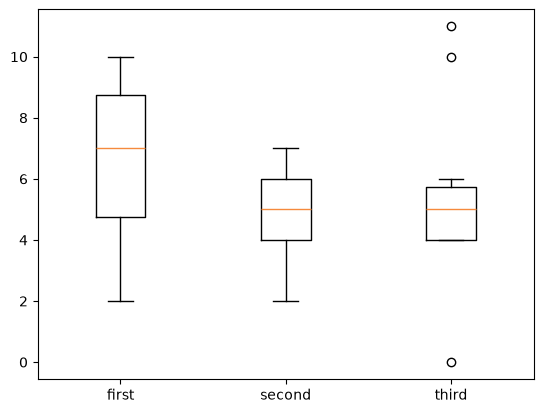

In [22]:
# boxplot shows a box plot for each of the columns in data
# here we stack the columns together from existing data with numpy column_stack() function
boxplotdata = np.column_stack((lineplotdata1, lineplotdata2, np.array([4,5,5,4,6,4,5,0,10,11])))
plt.boxplot(boxplotdata, tick_labels=['first', 'second', 'third'])
plt.show()

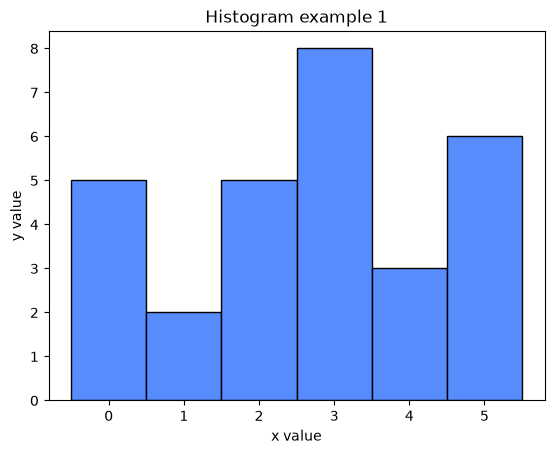

In [23]:
histdata = np.array([0,1,2,3,4,5,0,0,0,0,1,2,2,2,2,3,3,3,3,3,3,3,4,4,5,5,5,5,5])

# in .hist() bins parameter is number of intervals for the values, or the borders listed (like here)
# behaviour is not super intuitive
plt.hist(histdata, bins=range(7), edgecolor='black', align='left')
plt.title("Histogram example 1")
plt.xlabel("x value")
plt.ylabel("y value")
plt.show()